In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Para el proyecto cuyo cuadro se adjunta, un alumno ha entregado la siguiente resolución de la pregunta «¿qué probabilidad hay de terminar en 32 semanas o menos?»:

> *La ruta crítica es A - C - D - E - H - I, con duración media 30. La desviación típica del proyecto es la suma de las desviaciones típicas de sus actividades: σ = 0.5 + 0.2 + 1.0 + 0.6 + 0.4 + 1.0 = 3.7. Por tanto z = (32 − 30) / 3.7 = 0.54 y P = 0.706.*

Otro alumno ha usado la ruta A - C - D - E - G - I para calcular la desviación típica, obteniendo σ = 1.70.

In [3]:
pregunta_1 = "1. Compruebe la duración media y la ruta crítica.  "
pregunta_2 = "2. Localice el error del primer alumno y corrija el cálculo. ¿Sobrestima o subestima la probabilidad su error?  "
pregunta_3 = "3. ¿Qué error ha cometido el segundo alumno? ¿En qué caso su desviación típica sería la correcta?  "
pregunta_4 = "4. Dé la probabilidad correcta de terminar en 32 semanas o menos.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Compruebe la duración media y la ruta crítica.  

2. Localice el error del primer alumno y corrija el cálculo. ¿Sobrestima o subestima la probabilidad su error?  

3. ¿Qué error ha cometido el segundo alumno? ¿En qué caso su desviación típica sería la correcta?  

4. Dé la probabilidad correcta de terminar en 32 semanas o menos.  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation
    ('A'     , '---'      , 8       , 0.5               ),
    ('B'     , '---'      , 6       , 0.4               ),
    ('C'     , 'A,B'      , 3       , 0.2               ),
    ('D'     , 'C'        , 3       , 1                 ),
    ('E'     , 'D'        , 7       , 0.6               ),
    ('F'     , 'D'        , 1       , 0.4               ),
    ('G'     , 'E,F'      , 1       , 0.5               ),
    ('H'     , 'E'        , 3       , 0.4               ),
    ('I'     , 'G,H'      , 6       , 1                 ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation
activity,,,
A,---,8,0.5
B,---,6,0.4
C,"A,B",3,0.2
D,C,3,1.0
E,D,7,0.6
F,D,1,0.4
G,"E,F",1,0.5
H,E,3,0.4
I,"G,H",6,1.0


El proyecto corresponde a la instalación de una planta fotovoltaica sobre cubierta; las actividades son las siguientes (las duraciones del cuadro están en días).

In [5]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de sombras y producción',
    'B': 'Cálculo estructural de la cubierta',
    'C': 'Tramitación de permisos',
    'D': 'Acopio de módulos e inversores',
    'E': 'Montaje de la estructura soporte',
    'F': 'Colocación de módulos',
    'G': 'Cableado de corriente continua',
    'H': 'Instalación de inversores',
    'I': 'Cuadro de protecciones y contador',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de sombras y producción
B,Cálculo estructural de la cubierta
C,Tramitación de permisos
D,Acopio de módulos e inversores
E,Montaje de la estructura soporte
F,Colocación de módulos
G,Cableado de corriente continua
H,Instalación de inversores
I,Cuadro de protecciones y contador


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
plazo = 32

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Compruebe la duración media y la ruta crítica.  

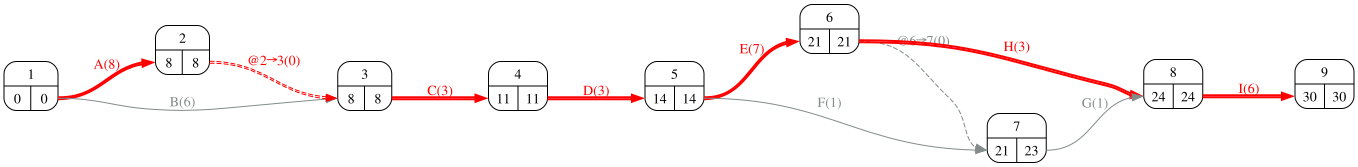

In [8]:
#| fig-cap: "Grafo PERT con tiempos y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [9]:
duracion_media = proyecto.duration(datos_proyecto['duration'])
camino_critico = proyecto.display_critical_path(datos_proyecto['duration'])

- Route_2 :	A, C, D, E, H, I <br> 

## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Localice el error del primer alumno y corrija el cálculo. ¿Sobrestima o subestima la probabilidad su error?  

Las varianzas de variables independientes se suman; las desviaciones típicas no. $\sigma_T = \sqrt{\sum \sigma_i^2}$, que es siempre menor que $\sum \sigma_i$. Al usar una σ demasiado grande el alumno obtiene un z demasiado pequeño y, para un plazo mayor que la media, una probabilidad demasiado baja (subestima).

In [11]:
desviacion_proyecto, varianza_rutas = proyecto.standard_deviation(datos_proyecto['duration'], datos_proyecto['variance'])
criticas = sorted(set(a for acts in proyecto.critical_path(datos_proyecto['duration']).values() for a in acts))
suma_sigmas = float(datos_proyecto.loc[criticas, 'standard_deviation'].sum())
pd.Series({'suma de σ (incorrecto)': suma_sigmas, 'raíz de la suma de varianzas (correcto)': desviacion_proyecto}).round(3).to_frame('σ del proyecto')

,σ del proyecto
suma de σ (incorrecto),3.700
raíz de la suma de varianzas (correcto),1.676


## Apartado 3

In [12]:
display(Markdown(pregunta_3))

3. ¿Qué error ha cometido el segundo alumno? ¿En qué caso su desviación típica sería la correcta?  

El segundo alumno ha sumado varianzas, que es lo correcto, pero de una ruta que no es la crítica. La varianza del proyecto se toma de la ruta crítica; sólo si esa otra ruta también fuera crítica (misma duración media) habría que considerarla, y entonces se tomaría la de mayor varianza.

## Apartado 4

In [13]:
display(Markdown(pregunta_4))

4. Dé la probabilidad correcta de terminar en 32 semanas o menos.  

In [14]:
z = (plazo - duracion_media) / desviacion_proyecto
Markdown(f'z = ({plazo} − {duracion_media}) / {desviacion_proyecto:.3f} = {z:.3f}; P(T ≤ {plazo}) = {norm.cdf(z):.3f}, frente al {0.706} del primer alumno.')

z = (32 − 30) / 1.676 = 1.193; P(T ≤ 32) = 0.884, frente al 0.706 del primer alumno.